In [29]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


In [30]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense, Input

In [31]:
df = pd.read_csv("files/Social_Network_Ads.csv")

In [32]:
df

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0
...,...,...,...,...,...
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0


In [33]:
df = df.iloc[:,2:]

In [34]:
df.sample(10)

,Age,EstimatedSalary,Purchased
64,59,83000,0
97,28,123000,1
11,26,52000,0
183,33,43000,0
16,47,25000,1
180,26,16000,0
32,21,16000,0
344,47,105000,1
150,26,15000,0
125,39,61000,0


<Axes: xlabel='Age', ylabel='EstimatedSalary'>

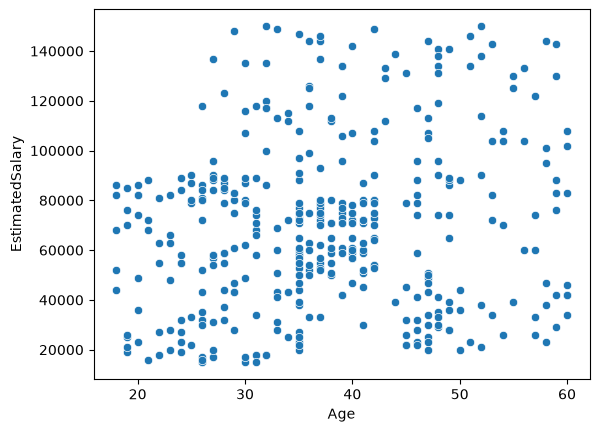

In [35]:
sns.scatterplot(x = df.iloc[:,0], y = df.iloc[:,1])

<Axes: xlabel='Age', ylabel='EstimatedSalary'>

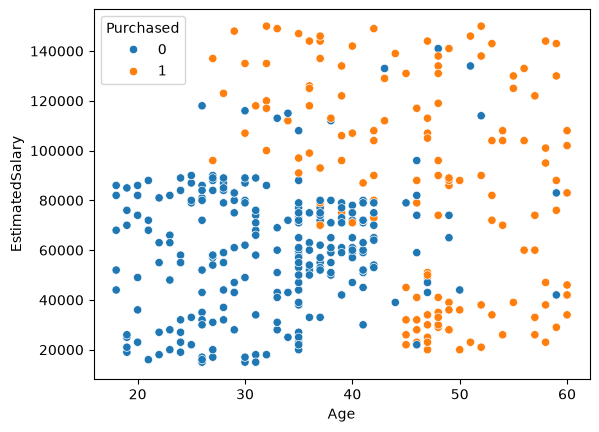

In [36]:
sns.scatterplot(data=df, x = "Age", y = "EstimatedSalary", hue="Purchased")

In [37]:
X = df.drop("Purchased",axis=1)
y = df["Purchased"]

In [38]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=2
)

In [39]:
model = Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(128,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [40]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 128)            │           384 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 513 (2.00 KB)

 Trainable params: 513 (2.00 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
model.compile(loss="binary_crossentropy",optimizer='adam', metrics=['accuracy'])

In [42]:
history = model.fit(X_train, y_train, validation_data=(X_test,y_test), epochs=100)

Epoch 1/100


10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 31ms/step - accuracy: 0.5219 - loss: 203.4728 - val_accuracy: 0.6000 - val_loss: 226.4953
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5344 - loss: 141.4546 - val_accuracy: 0.6000 - val_loss: 175.0968
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5000 - loss: 75.4955 - val_accuracy: 0.4000 - val_loss: 44.2572
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5531 - loss: 39.2050 - val_accuracy: 0.4000 - val_loss: 108.0894
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5219 - loss: 59.6585 - val_accuracy: 0.6000 - val_loss: 156.3840
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5469 - loss: 104.2233 - val_accuracy: 0.6000 - val_loss: 80.3445
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.5031 - loss: 39.0769 - val_accuracy: 0.6000 - val_loss: 83.4901
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.5406 - loss: 65.2541 - val_ac

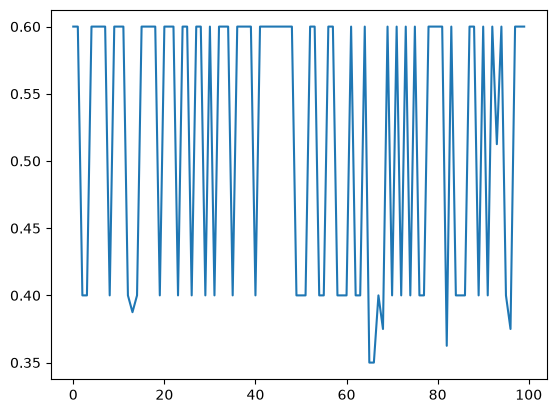

In [43]:
plt.plot(history.history['val_accuracy'])

# Normalization vs standardization

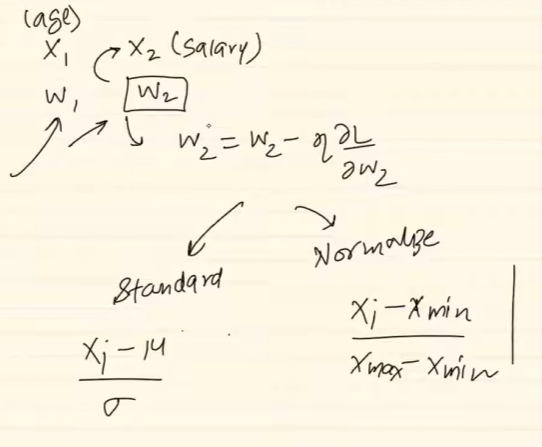
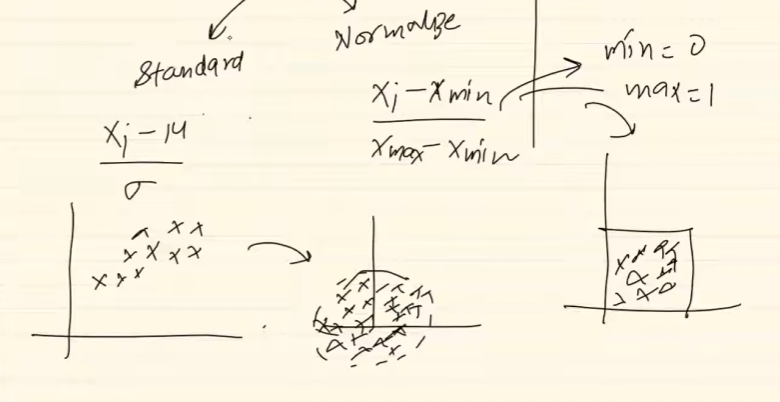

# Applied Scaling

In [45]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [49]:
X_train_scaled[:,0]

array([ 0.88928823, -0.17254846, -1.04132394,  0.98581884, -0.94479333,
        0.40663519,  0.98581884,  0.31010458,  1.7580637 , -0.17254846,
        1.7580637 , -1.33091576,  2.04765553,  1.27541066, -1.13785454,
       -0.36560968, -1.71703819, -0.5586709 ,  0.31010458,  0.02051275,
        0.02051275, -0.07601785, -0.6552015 ,  0.02051275,  0.31010458,
       -0.46214029, -0.75173211, -0.26907907, -1.13785454, -0.07601785,
        0.02051275, -1.13785454,  1.08234944, -0.26907907,  1.37194127,
       -1.42744637, -0.94479333,  1.95112492,  0.88928823, -1.13785454,
        0.02051275,  0.79275762, -0.26907907,  0.88928823,  0.31010458,
       -0.26907907, -0.26907907,  1.46847188, -0.07601785, -0.84826272,
       -0.07601785, -0.26907907,  0.21357397, -0.26907907,  0.11704336,
        1.95112492, -1.04132394,  0.31010458,  2.04765553, -1.13785454,
        0.21357397, -0.26907907, -0.6552015 ,  0.21357397,  0.40663519,
       -1.13785454, -0.07601785,  1.08234944,  0.88928823, -0.07

<Axes: >

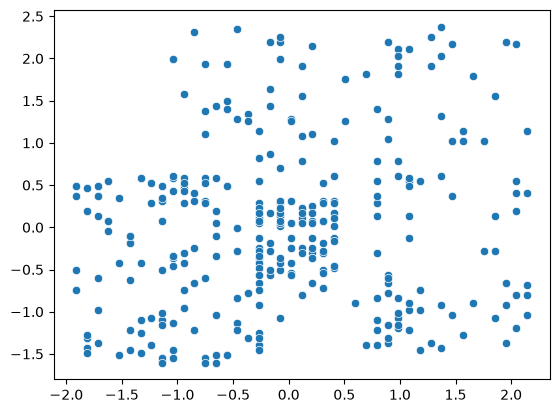

In [51]:
sns.scatterplot(x = X_train_scaled[:,0], y = X_train_scaled[:,1])

In [52]:
model = Sequential()
model.add(Input(shape=(2,)))
model.add(Dense(128,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [53]:
model.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])

history = model.fit(X_train_scaled, y_train, validation_data=(X_test_scaled, y_test), epochs=100)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step - accuracy: 0.7500 - loss: 0.6588 - val_accuracy: 0.7875 - val_loss: 0.6227
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.7906 - loss: 0.6042 - val_accuracy: 0.8000 - val_loss: 0.5679
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8031 - loss: 0.5580 - val_accuracy: 0.7875 - val_loss: 0.5227
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8156 - loss: 0.5185 - val_accuracy: 0.7875 - val_loss: 0.4856
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8219 - loss: 0.4856 - val_accuracy: 0.7875 - val_loss: 0.4535
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8219 - loss: 0.4559 - val_accuracy: 0.7875 - val_loss: 0.4265
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8281 - loss: 0.4304 - val_accuracy: 0.8000 - val_loss: 0.4039
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8469 - loss: 0.4085 - val_accuracy: 0.80

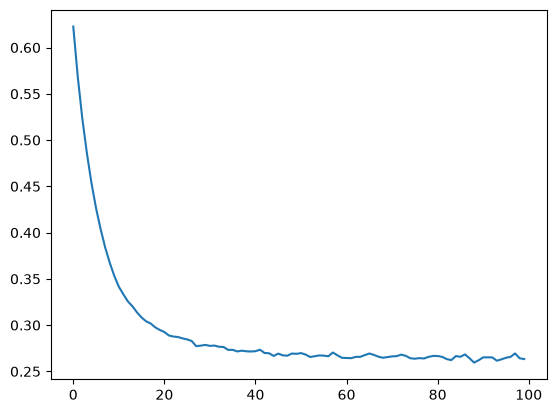

In [54]:
plt.plot(history.history['val_loss'])